---
title: "Лабораторна робота 3. Валідація та аудит достовірності результатів машинного навчання"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib
format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


::: {.callout-note}
## Місце роботи в курсі
ЛР1 -- *ML/KDD Research Specification v0.1*; ЛР2 -- *ML Experiment Design v0.2*; ЛР3 -- *Validation & Evidence Audit v0.3*. Цього разу не шукаємо складнішу модель: перевіряємо, чи справді отримані результати підтримують наукове твердження.
:::

## Мета роботи
Сформувати практичні навички аудиту достовірності ML-результатів: перевіряти відповідність розбиття даних дослідницькому питанню, виявляти витік інформації, оцінювати стійкість і невизначеність порівнянь, документувати загрози валідності та формулювати наукове твердження з чіткими межами застосовності.

## Завдання роботи
1. Відтворити контрольований ML-експеримент.
2. Порівняти випадкове та групове розбиття.
3. Виявити й усунути витік інформації між train і test.
4. Застосувати групову перехресну перевірку.
5. Оцінити невизначеність різниці якості двох моделей.
6. Перевірити стійкість до зміни складу тестових груп.
7. Скласти матрицю загроз валідності.
8. Оновити протокол власного дослідження до v0.3.

## Теоретичні відомості

Нехай $f_A$ та $f_B$ -- дві моделі, а $L$ -- функція втрат. Порівнювана величина:

$$
\Delta = \mathbb{E}_{(X,Y)\sim P_{\mathrm{target}}}
\left[L(Y,f_A(X))-L(Y,f_B(X))\right].
$$

Значення $\widehat{\Delta}$ залежить від того, *яку популяцію репрезентує тестова вибірка*. Навіть коректна реалізація алгоритму не компенсує неправильного розбиття [@hastie2009elements; @breiman2001two].

Розрізняємо внутрішню, зовнішню, конструктну й статистичну валідність. Для задачі з повторними вимірюваннями незалежною одиницею часто є *суб'єкт*, а не рядок таблиці.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("RQ і цільова<br/>популяція") --> B("Одиниця<br/>незалежності")
 B --> C("Коректне<br/>розбиття")
 C --> D("Baseline і<br/>candidate")
 D --> E("Невизначеність<br/>та robustness")
 E --> F("Матриця загроз<br/>валідності")
 F --> G("Evidence<br/>Audit v0.3")
```

# Частина I. Навчальний експеримент

## 1. Дослідницька постановка
Розглянемо *синтетичні* дані з повторними спостереженнями від суб'єктів. Кожний суб'єкт має власний профіль ознак, а мітка призначається випадково на рівні суб'єкта. Мета -- продемонструвати, чому майже ідеальна якість на випадковому розбитті рядків не доводить здатності узагальнювати на *нових суб'єктів*.

Це демонстрація механізму leakage, а не емпіричний результат щодо реальних користувачів, пацієнтів або платформ.

## 2. Генерація контрольованих даних


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.base import clone

SEED = 42
rng = np.random.default_rng(SEED)
n_subjects, n_records, n_features = 120, 8, 12
profiles = rng.normal(size=(n_subjects, n_features))
subject_labels = rng.integers(0, 2, size=n_subjects)
X = np.repeat(profiles, n_records, axis=0)
X += rng.normal(scale=0.08, size=X.shape)
y = np.repeat(subject_labels, n_records)
groups = np.repeat(np.arange(n_subjects), n_records)

pd.DataFrame({
    "n_rows": [len(y)],
    "n_subjects": [len(np.unique(groups))],
    "positive_rate": [y.mean()],
    "records_per_subject": [n_records]
})


,n_rows,n_subjects,positive_rate,records_per_subject
0,960,120,0.5,8


## 3. Два протоколи валідації
*Протокол A* -- випадкове розбиття рядків. *Протокол B* -- розбиття за суб'єктами без перетину груп. Обидва протоколи виконуються на тих самих даних, але відповідають *різним питанням узагальнення*.


In [2]:
indices = np.arange(len(y))
row_tr, row_te = train_test_split(
    indices, test_size=0.25, stratify=y, random_state=SEED
)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
group_tr, group_te = next(splitter.split(X, y, groups=groups))

def assess_split(train_idx, test_idx):
    model = KNeighborsClassifier(n_neighbors=1)
    model.fit(X[train_idx], y[train_idx])
    pred = model.predict(X[test_idx])
    return {
        "accuracy": accuracy_score(y[test_idx], pred),
        "balanced_accuracy": balanced_accuracy_score(y[test_idx], pred),
        "shared_subjects": len(set(groups[train_idx]) & set(groups[test_idx])),
        "test_subjects": len(np.unique(groups[test_idx]))
    }

pd.DataFrame([
    {"protocol": "Random row split", **assess_split(row_tr, row_te)},
    {"protocol": "Group split", **assess_split(group_tr, group_te)}
]).round(3)


,protocol,accuracy,balanced_accuracy,shared_subjects,test_subjects
0,Random row split,1.000,1.00,102,102
1,Group split,0.517,0.52,0,30


### Завдання 3.1
Поясніть різницю між *високою якістю на відомих суб'єктах* і *узагальненням на нових суб'єктів*. Чи можна назвати випадковий split помилковим за будь-якого RQ? Чому відповідь залежить від цільової популяції?

## 4. Аудит витоку інформації
Перевіримо інваріант, який має виконуватися за group split:

$$
G_{\mathrm{train}}\cap G_{\mathrm{test}}=\varnothing.
$$


In [3]:
train_subjects = set(groups[group_tr])
test_subjects = set(groups[group_te])
assert train_subjects.isdisjoint(test_subjects)
print("Перетин груп train/test:", len(train_subjects & test_subjects))
print("Частка рядків із відомими групами у random test:",
      np.isin(groups[row_te], groups[row_tr]).mean())


Перетин груп train/test: 0
Частка рядків із відомими групами у random test: 1.0


## 5. GroupKFold і чесний baseline
Оцінимо *один і той самий* класифікатор на п'яти розбиттях без перетину суб'єктів. Додамо наївний baseline, який прогнозує найчастіший клас *навчального fold*.

У цьому синтетичному сценарії очікуємо, що 1-NN не матиме надійної переваги на нових суб'єктах, оскільки мітки призначено випадково.


In [4]:
cv = GroupKFold(n_splits=5)
models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "1-NN": KNeighborsClassifier(n_neighbors=1)
}
rows = []
for fold, (tr, te) in enumerate(cv.split(X, y, groups), start=1):
    assert set(groups[tr]).isdisjoint(set(groups[te]))
    for name, estimator in models.items():
        model = clone(estimator).fit(X[tr], y[tr])
        pred = model.predict(X[te])
        rows.append({
            "fold": fold,
            "model": name,
            "accuracy": accuracy_score(y[te], pred),
            "balanced_accuracy": balanced_accuracy_score(y[te], pred),
            "n_test_subjects": len(np.unique(groups[te]))
        })
cv_results = pd.DataFrame(rows)
display(cv_results.round(3))
display(cv_results.groupby("model")[["accuracy","balanced_accuracy"]].agg(["mean","std"]).round(3))


,fold,model,accuracy,balanced_accuracy,n_test_subjects
0,1,Dummy,0.458,0.500,24
1,1,1-NN,0.542,0.531,24
2,2,Dummy,0.458,0.500,24
3,2,1-NN,0.526,0.532,24
4,3,Dummy,0.500,0.500,24
5,3,1-NN,0.458,0.458,24
6,4,Dummy,0.417,0.500,24
7,4,1-NN,0.568,0.574,24
8,5,Dummy,0.417,0.500,24
9,5,1-NN,0.594,0.612,24


accuracy        balanced_accuracy       
          mean    std              mean    std
model                                         
1-NN     0.538  0.051             0.542  0.057
Dummy    0.450  0.035             0.500  0.000

### Завдання 5.1
Чому стандартне відхилення fold-метрик не слід автоматично інтерпретувати як довірчий інтервал? Який baseline є змістовним у Вашій дисертаційній задачі?

## 6. Парний bootstrap за незалежними одиницями
Оцінимо різницю accuracy між 1-NN та Dummy на *тих самих* тестових суб'єктах. Повторні рядки одного суб'єкта залежні, тому bootstrap здійснюємо за суб'єктами, а не окремими рядками.

Тут навчені моделі залишаються фіксованими; інтервал відображає варіативність складу тестових суб'єктів, але *не* невизначеність повторного навчання.


In [5]:
model_a = KNeighborsClassifier(n_neighbors=1).fit(X[group_tr], y[group_tr])
model_b = DummyClassifier(strategy="most_frequent").fit(X[group_tr], y[group_tr])
pa = model_a.predict(X[group_te])
pb = model_b.predict(X[group_te])

test_groups = groups[group_te]
unique_test_groups = np.unique(test_groups)
per_group = []
for g in unique_test_groups:
    mask = test_groups == g
    per_group.append({
        "group": int(g),
        "delta": float(np.mean(pa[mask] == y[group_te][mask])
                       - np.mean(pb[mask] == y[group_te][mask]))
    })
group_delta = pd.DataFrame(per_group)
rng_boot = np.random.default_rng(SEED + 1)
B = 2000
samples = rng_boot.choice(
    group_delta["delta"].to_numpy(),
    size=(B, len(group_delta)),
    replace=True
)
boot_means = samples.mean(axis=1)
print("Mean paired delta:", round(group_delta["delta"].mean(), 3))
print("95% bootstrap percentile interval:",
      np.quantile(boot_means, [0.025, 0.975]).round(3))


Mean paired delta: 0.05
95% bootstrap percentile interval: [-0.188  0.275]


## 7. Візуалізація стійкості
Побудуємо розподіл bootstrap-оцінок. Якщо інтервал охоплює нуль, це не доводить рівності моделей; якщо не охоплює -- висновок усе одно обмежений припущеннями про вибірку та процедурою bootstrap.


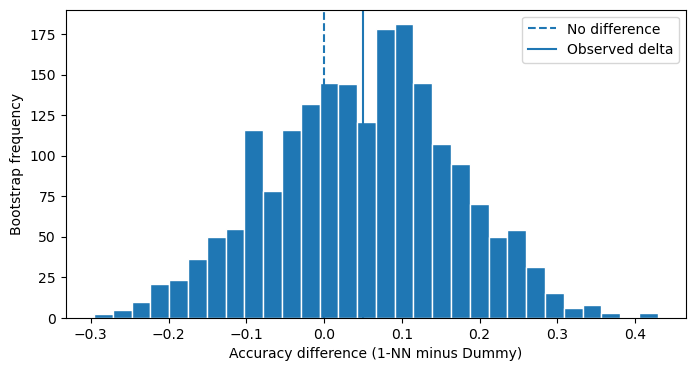

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_means, bins=30, edgecolor="white")
ax.axvline(0, linestyle="--", label="No difference")
ax.axvline(group_delta["delta"].mean(), linestyle="-", label="Observed delta")
ax.set_xlabel("Accuracy difference (1-NN minus Dummy)")
ax.set_ylabel("Bootstrap frequency")
ax.legend()
plt.show()


## 8. Матриця загроз валідності
Заповніть таблицю за результатами експерименту.

| Вид валідності | Питання | Загроза | Контроль / залишкове обмеження |
|---|---|---|---|
| Внутрішня | Чи порівняння відповідає протоколу? | Перетин суб'єктів | |
| Зовнішня | Чи переносимо результат на нові групи? | Відмінний цільовий домен | |
| Конструктна | Чи мітка вимірює потрібне явище? | Випадкова синтетична мітка | |
| Статистична | Чи достатньо обґрунтована різниця? | Залежність рядків | |

### Завдання 8.1
Сформулюйте *підтримуване* та *непідтримуване* наукові твердження. Поясніть, чому висока random-split accuracy не є свідченням наявності узагальнюваної закономірності.

# Частина II. Перенесення на дисертаційне дослідження

## 9. Аудит протоколу v0.2
Поверніться до власного **ML Experiment Design v0.2** з ЛР2. Не змінюйте заднім числом уже зафіксовані експериментальні рішення: усі виправлення оформлюйте як нову версію з причиною.

| Елемент | Рішення у v0.2 | Виявлена загроза | Зміна у v0.3 |
|---|---|---|---|
| Research Question | | | |
| Одиниця незалежності | | | |
| Train/validation/test | | | |
| Baseline | | | |
| Primary metric | | | |
| Leakage controls | | | |
| Target population | | | |

## 10. Незалежність спостережень і схема розбиття
Визначте реальну одиницю незалежності: користувач, пацієнт, пристрій, часовий блок, документ, графова компонента тощо. Обґрунтуйте, чи потрібні `GroupKFold`, `TimeSeriesSplit`, temporal holdout, external validation або інша схема.

## 11. Аудит витоку даних
Перевірте: повторні об'єкти; майбутні ознаки; preprocessing поза CV; feature selection на повній вибірці; target leakage; дублікати; непряме використання test для вибору гіперпараметрів. Для кожної загрози зафіксуйте механізм, тест перевірки та спосіб усунення.

## 12. Невизначеність і robustness
Визначте, *що саме* є одиницею ресемплінгу. Для залежних даних не використовуйте наївний row bootstrap без обґрунтування. Проведіть щонайменше одну заплановану перевірку стійкості (зміна seed, допустимий альтернативний split, часовий період або підпопуляція) та поясніть, чи зберігається знак і порядок величини ефекту.

## 13. Реєстр експериментальних рішень
Збережіть версію даних, код, seed, залежності, конфігурацію моделей, метрики, правила вибору гіперпараметрів і дату фіксації протоколу. Розрізняйте *відтворюваність* того самого аналізу та *реплікованість* результату на незалежних даних.

## 14. Наукове твердження і його межі
Завершіть роботу трьома формулюваннями:

- **Evidence:** що конкретно виміряно, на яких даних і з якою невизначеністю?
- **Claim:** яке твердження ці дані підтримують?
- **Limitations:** які твердження залишаються поза межами доказів?

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Research<br/>Specification v0.1") --> B("Experiment<br/>Design v0.2")
 B --> C("Validation<br/>Audit v0.3")
 C --> D("Evidence")
 D --> E("Claim з<br/>обмеженнями")
```

## 15. Підсумковий артефакт
Підготуйте **Validation & Evidence Audit v0.3**, що містить: RQ, target population, одиницю незалежності, обґрунтування split, leakage audit, baseline comparison, оцінювання невизначеності, одну robustness-перевірку, матрицю загроз валідності, відтворюваний протокол та обмежене наукове твердження.

# Контрольні питання
1. Чому незалежна одиниця аналізу може не збігатися з рядком?
2. Коли random split відповідає RQ, а коли -- ні?
3. Що таке group leakage?
4. Як перевірити перетин груп між train і test?
5. Чому `GroupKFold` не гарантує зовнішньої валідності?
6. Чому preprocessing слід навчати лише на train fold?
7. Чим відрізняються внутрішня та зовнішня валідність?
8. Що таке конструктна валідність?
9. Яку невизначеність відображає парний bootstrap?
10. Чому bootstrap за рядками може бути хибним?
11. Чим robustness відрізняється від пошуку найкращого seed?
12. Яке твердження не можна робити за високої random-split accuracy?
13. Що слід зафіксувати для відтворюваності?
14. Як відрізнити наукове твердження від надмірного узагальнення?

# Вимоги до звіту
Надайте короткий опис навчального експерименту, порівняльну таблицю split-протоколів, CV та bootstrap-результати, матрицю загроз валідності й **Validation & Evidence Audit v0.3** для власної теми. Код і таблиці повинні дозволяти відтворити висновок.

# Висновки
Аудит ML-експерименту повинен відповідати на питання не лише *«яку якість отримано?»*, а насамперед *«за яких припущень, на якій популяції та з якою доказовою силою отримано результат?»*. У ЛР4 переходимо до виявлення й валідації прихованої структури даних.

# Література
[@hastie2009elements; @breiman2001two; @vapnik1998statistical]

::: {#refs}
:::
